### Visualize dimension CCGP of feature beliefs, pre-stimulus
Runs of `scripts/pseudo_decoding/belief_partitions/dim_ccgp_feat_beliefs.py`, design in `claude_notes/dimension_ccgp_design_brainstorm.md`.

For each quadruple [X, X', Y, Y'] (X, X' share dimension A, Y, Y' share dimension B), decoders labelled by dimension are trained on High X vs High Y and tested on High X' vs High Y', over all 4 such assignments.
- **train pair**: held-out accuracy on the decoder's own training pair
- **CCGP**: accuracy on the other pair

Shuffles are session permuted. Error bands are SE over quadruples x assignments x splits, as in the pref decoders. Significance bars are the stored p values of `compute_p_vals_for_dim_ccgp.py`, true vs shuffle per bin (thin p < 0.05, medium p < 0.01, thick p < 0.001).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import argparse
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

import utils.visualization_utils as visualization_utils
from scripts.pseudo_decoding.belief_partitions.belief_partition_configs import *
import scripts.pseudo_decoding.belief_partitions.belief_partitions_io as belief_partitions_io
from scripts.pseudo_decoding.belief_partitions.generate_dim_quads import QUADS_PATH

In [2]:
quads = pd.read_pickle(QUADS_PATH)

args = argparse.Namespace(
    **BeliefPartitionConfigs()._asdict()
)
args.subject = "both"
args.trial_event = "StimOnset"
args.mode = "dim_ccgp"
args.sig_unit_level = "pref_99th_no_cond_window_filter_drift"
args.base_output_path = "/data/patrick_res/dim_ccgp"

res = belief_partitions_io.read_dim_ccgp_results(args, quads, num_shuffles=10)
p_vals = pd.read_pickle(os.path.join(belief_partitions_io.get_dir_name(args, make_dir=False), "dim_ccgp_p_vals.pickle"))

In [3]:
# long format, one row per (run row, measure), with the earlier pair CCGP figure's colors
MEASURE_TO_DISPLAY = {"train_pair_acc": "train pair", "ccgp_acc": "CCGP"}
COND_TO_COLOR = {
    "train pair": "#1b9e77",
    "train pair shuffle": "#b3e2cd",
    "CCGP": "#d95f02",
    "CCGP shuffle": "#fdcdac",
}
long_res = res.melt(
    id_vars=["quad_str", "assignment_idx", "split_idx", "shuffle_idx", "shuffle_type", "Time", "TimeIdx"],
    value_vars=list(MEASURE_TO_DISPLAY), var_name="measure", value_name="Accuracy",
)
long_res["condition"] = long_res.measure.map(MEASURE_TO_DISPLAY) + np.where(long_res.shuffle_type == "shuffle", " shuffle", "")

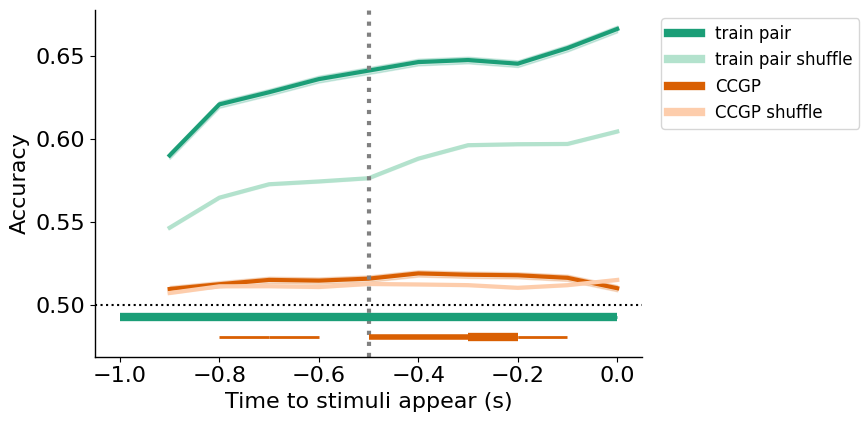

In [4]:
plt.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(
    long_res, x="Time", y="Accuracy", hue="condition", hue_order=list(COND_TO_COLOR),
    palette=COND_TO_COLOR, linewidth=3, errorbar="se", ax=ax,
)
ax.axhline(0.5, linestyle="dotted", color="black")
ax.axvline(-.5, color='grey', linestyle='dotted', linewidth=3)

# significance bars below the lines, one row per measure, in that measure's color
y_min, y_max = ax.get_ylim()
interval = (y_max - y_min) / 15
for i, (measure, display) in enumerate(MEASURE_TO_DISPLAY.items()):
    visualization_utils.plot_sig_bars(p_vals[p_vals.measure == measure], y_min - interval * (i + 0.5), ax, color=COND_TO_COLOR[display])
ax.set_ylim(bottom=y_min - interval * (len(MEASURE_TO_DISPLAY) + 0.5))

ax.set_xlabel("Time to stimuli appear (s)")
ax.set_ylabel("Accuracy")
legend = ax.legend(fontsize=12, loc="upper left", bbox_to_anchor=(1.02, 1))
for line in legend.get_lines():
    line.set_linewidth(6)
visualization_utils.format_plot([ax])
fig.tight_layout()

In [5]:
# mean accuracy per bin and condition, next to the p values
means = long_res.groupby(["Time", "condition"]).Accuracy.mean().unstack()[list(COND_TO_COLOR)]
ps = p_vals.pivot(index="Time", columns="measure", values="p").rename(columns=lambda m: f"p {MEASURE_TO_DISPLAY[m]}")
means.join(ps).round(3)

,train pair,train pair shuffle,CCGP,CCGP shuffle,p CCGP,p train pair
Time,,,,,,
-0.9,0.590,0.546,0.509,0.507,0.111,0.0
-0.8,0.621,0.565,0.512,0.511,0.292,0.0
-0.7,0.628,0.573,0.515,0.511,0.042,0.0
-0.6,0.636,0.574,0.515,0.511,0.037,0.0
-0.5,0.641,0.576,0.516,0.513,0.086,0.0
-0.4,0.646,0.588,0.519,0.512,0.001,0.0
-0.3,0.648,0.596,0.518,0.512,0.003,0.0
-0.2,0.645,0.597,0.518,0.510,0.000,0.0
-0.1,0.655,0.597,0.516,0.512,0.023,0.0
